## Investigating Differences in Temperature and Precipitation between CMIP5 and CMIP6

In this exercise, you'll be familiarizing yourself with the best method for downloading CMIP6 data. Data from CMIP6 will be used throughout this module to compare to other data sources and perform similar analysis you read about in the text. By the end of this lab you should be comfortable downloading data for this module and hopefully your own future research.

## Data catalogs

The file `https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv` in google cloud storage contains thousands of lines of metadata, each describing an individual climate model experiment's simulated data.

For example, the first line in the csv file contains the precipitation rate (`variable_id = 'pr'`), as a function of latitude, longitude, and time, in an individual climate model experiment with the BCC-ESM1 model (`source_id = 'BCC-ESM1'`) developed by the Beijing Climate Center (`institution_id = 'BCC'`). The model is *forced* by the forcing experiment SSP370 (`experiment_id = 'ssp370'`), which stands for the Shared Socio-Economic Pathway 3 that results in a change in radiative forcing of $\Delta F = 7.0$ W/m$^{2}$ from pre-industrial to 2100. This simulation was run as part of the `AerChemMIP` activity, which is a spin-off of the CMIP activity that focuses specifically on how aerosol chemistry affects climate.

In [5]:
import pandas as pd

df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


Here, we show the various forcing experiments that climate modellers ran in these simulations.

In [8]:
# need to print better
exp = df['experiment_id'].unique()
exp

<ArrowStringArray>
[ 'highresSST-present',           'piControl',        'control-1950',
           'hist-1950',          'historical',                'amip',
        'abrupt-4xCO2',        'abrupt-2xCO2',      'abrupt-0p5xCO2',
             '1pctCO2',
 ...
        'pa-futArcSIC',            'pa-pdSIC',      'historical-ext',
  'pdSST-futArcSICSIT', 'pdSST-futOkhotskSIC',  'pdSST-futBKSeasSIC',
         'pa-piArcSIC',         'pa-piAntSIC',        'pa-futAntSIC',
      'pdSST-pdSICSIT']
Length: 170, dtype: str

### Create Data Query to Download the CMIP6 Data From the Archive

This notebook uses [`intake-esm`](https://intake-esm.readthedocs.io/en/latest/) to ingest and organize climate model output from CMIP6. 

In [4]:
### Load the necessary packages ###
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np
import dask
from dask.diagnostics import progress
from tqdm.autonotebook import tqdm
import intake
import fsspec
import seaborn as sns
from collections import defaultdict

### Load the CMIP6 archive using intake-esm ###
col = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json") #load in data from intake-esm for CMIP6



In [ ]:

### Create the data query ###
expts = ['1pctCO2'] # grab data for 1pctCO2 experiment
variables = ['tas','pr'] # grab data for near-surface air temperature and precipitation
query = dict(
    experiment_id=expts,
    table_id='Amon', # choose to look at atmospheric variables (A) saved at monthly resolution (mon)
    variable_id=variables, 
    member_id = 'r1i1p1f1', # pick the r1i1p1f1 initialization (usually seen as the default realization or set of initial conditions)
)


### Grab the data which meets our specifications ###
col_subset = col.search(require_all_on=["source_id"], **query) #Grab subset of CMIP6 data that we need


### Check Data to be Downloaded

Let's now take a look at the subset of the data we have selected in our query. How many models are included? Ensure that both 'tas' and 'pr' are included for each variable.

In [2]:
# col_subset.df.groupby("source_id")[
#     ["experiment_id", "variable_id", "table_id"] 
# ].nunique() #Grab subset of CMIP6 data that we need

num_models = len(col_subset.keys()) #the number of keys in the dataset will tell us the number of models
vars_incl = col_subset.df.groupby("source_id")['variable_id'].unique() #this will tell us the variables included for each model  

print('Number of Models: ',num_models)
print('Variables Included:',vars_incl)

Number of Models:  49
Variables Included: source_id
ACCESS-CM2           [pr, tas]
ACCESS-ESM1-5        [pr, tas]
AWI-CM-1-1-MR        [pr, tas]
AWI-ESM-1-1-LR       [tas, pr]
BCC-CSM2-MR          [pr, tas]
BCC-ESM1             [pr, tas]
CAMS-CSM1-0          [tas, pr]
CAS-ESM2-0           [tas, pr]
CESM2                [pr, tas]
CESM2-WACCM          [pr, tas]
CESM2-WACCM-FV2      [pr, tas]
CIESM                [pr, tas]
CMCC-CM2-HR4         [pr, tas]
CMCC-CM2-SR5         [pr, tas]
CMCC-ESM2            [pr, tas]
CanESM5              [tas, pr]
E3SM-1-0             [tas, pr]
EC-Earth3-AerChem    [tas, pr]
EC-Earth3-CC         [tas, pr]
EC-Earth3-Veg        [tas, pr]
FGOALS-f3-L          [tas, pr]
FGOALS-g3            [pr, tas]
FIO-ESM-2-0          [pr, tas]
GFDL-CM4             [tas, pr]
GFDL-ESM4            [tas, pr]
GISS-E2-1-G          [tas, pr]
GISS-E2-1-H          [tas, pr]
GISS-E2-2-G          [tas, pr]
GISS-E2-2-H          [pr, tas]
ICON-ESM-LR          [tas, pr]
IITM-ESM          

### Download the CMIP6 Data From the Archive

So far, we've only provided our search query, and double checked that all variables are included. Now we are going to store the datasets in a dictionary, and do some preprocessing of the data so standardize it. This includes loading the data into memory using Dask, removing unnecessary dimensions (like 'time_bounds' or 'bounds'), and merging the datasets into a common dataset:

In [ ]:
### Create some necessary functions to pre-process the data ###
def drop_all_bounds(ds): # function which removes dimensions like time_bounds or bounds, which are not needed here 
    """Drop coordinates like 'time_bounds' from datasets,
    which can lead to issues when merging."""
    drop_vars = [vname for vname in ds.coords
                 if (('_bounds') in vname ) or ('_bnds') in vname]
    return ds.drop(drop_vars)

def open_dsets(df): # function which opens zarr dataset and executes the drop_all_bounds() function
    """Open datasets from cloud storage and return xarray dataset."""
    dsets = [xr.open_zarr(fsspec.get_mapper(ds_url, token='anon'), consolidated=True)
             .pipe(drop_all_bounds)
             for ds_url in df.zstore]
    try:
        ds = xr.merge(dsets, join='exact')
        return ds
    except ValueError:
        return None

def open_delayed(df): # function to load dataset into memory using Dask
    """A dask.delayed wrapper around `open_dsets`.
    Allows us to open many datasets in parallel."""
    return dask.delayed(open_dsets)(df)

### Store datasets in dictionary ###
dsets = defaultdict(dict) # store datasets in a dictionary 

### Loop through models and load into memory using Dask ###
for group, df in col_subset.df.groupby(by=['source_id', 'experiment_id']):
    dsets[group[0]][group[1]] = open_delayed(df)

dsets_ = dask.compute(dict(dsets))[0] #up until this point, no computation has been done. It is only here that the data is processed.


C:\Users\madel\AppData\Local\Temp\ipykernel_33004\945188819.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates prior reform date (1582-10-15). To silence this warning specify 'use_cftime=True'.
  dsets = [xr.open_zarr(fsspec.get_mapper(ds_url, token='anon'), consolidated=True)
c:\Users\madel\Code\CREATE-Modules\ESM_clean\esm_3.12\Lib\site-packages\xarray\coding\times.py:215: SerializationWarning: Ambiguous reference date string: 950-01-01. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0950-01-01). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)
C:\Users\madel\AppData\Local\Temp\ipykernel_33004\945188819.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing 

### Investigate the datasets

Let's take a look at the datasets included, before we calculate their global means. You'll notice that the metadata for 3 of the models is missing (GISS-E2-2-H, KIOST-ESM, and NorESM2-LM): 

In [6]:
print(dsets_)

{'ACCESS-CM2': {'1pctCO2': <xarray.Dataset> Size: 398MB
Dimensions:  (time: 1800, lat: 144, lon: 192)
Coordinates:
  * time     (time) object 14kB 0950-01-16 12:00:00 ... 1099-12-16 12:00:00
  * lat      (lat) float64 1kB -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
    height   float64 8B ...
Data variables:
    pr       (time, lat, lon) float32 199MB dask.array<chunksize=(495, 144, 192), meta=np.ndarray>
    tas      (time, lat, lon) float32 199MB dask.array<chunksize=(668, 144, 192), meta=np.ndarray>
Attributes: (12/48)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.4.0
    ...                     ...
    table_info:             Creation Date:(30 April 2019) MD5:e14f55f257cceaf...
    title:                  ACCESS-CM2 output prepared for CMIP

### Calculate the Global Mean Values

Now that we've loaded the data from each of the individual models into memory, and stored them in a common dataset, we will next calculate the global mean values for each model and variable combination:

In [7]:
### Create functions to calculate global mean values for each model ###

def get_lat_name(ds): # function to check whether latitude coordinate is 'lat' or 'latitude' as different models may have different names for lat/lon
    for lat_name in ['lat', 'latitude']:
        if lat_name in ds.coords:
            return lat_name
    raise RuntimeError("Couldn't find a latitude coordinate")

def global_mean(ds): # function which calculates the global mean value for each variable in the dataset
    lat = ds[get_lat_name(ds)]
    weight = np.cos(np.deg2rad(lat))
    weight /= weight.mean()
    other_dims = set(ds.dims) - {'time'}
    return (ds * weight).mean(other_dims)

### Calculate global mean values for each of the datasets, and resample to annual means ### 

expt_da = xr.DataArray(expts, dims='experiment_id',
                       coords={'experiment_id': expts}) # create data-array with dimensions and coordinates of experiment_id

print(expt_da)

dsets_aligned = {} # initalize an empty dictionary to store global mean data in

for k, v in tqdm(dsets_.items()): #loop through each model and variable
    expt_dsets = v.values()
    if any([d is None for d in expt_dsets]):
        print(f"Missing experiment for {k}")
        continue

    for ds in expt_dsets:
        ds.coords['year'] = ds.time.dt.year - ds.time.dt.year[0]

    # workaround for
    # https://github.com/pydata/xarray/issues/2237#issuecomment-620961663
    dsets_ann_mean = [v[expt].pipe(global_mean)
                             .swap_dims({'time': 'year'})
                             .drop('time')
                             .coarsen(year=12).mean() #calculate annual mean
                      for expt in expts] #calculate global, annual means for each variable and model

    # add information about experiment_id
    dsets_aligned[k] = xr.concat(dsets_ann_mean, join='right',
                                 dim=expt_da)

with progress.ProgressBar():
    dsets_aligned_ = dask.compute(dsets_aligned)[0] #do the computation using Dask delayed execution

<xarray.DataArray (experiment_id: 1)> Size: 28B
array(['1pctCO2'], dtype='<U7')
Coordinates:
  * experiment_id  (experiment_id) <U7 28B '1pctCO2'


  0%|          | 0/49 [00:00<?, ?it/s]

/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022

Missing experiment for GISS-E2-2-H
Missing experiment for KIOST-ESM


/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022646539.py:38: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
/tmp/ipykernel_4184307/4022

Missing experiment for NorESM2-LM
[########################################] | 100% Completed | 188.14 s


### Take A Look At Global Mean Files

Notice that 3 of the models (GISS-E2-2-H, KIOST-ESM, and NorESM2-LM) were not downloaded correctly, as a result of their missing metadata. Now that we've calculated the global mean values for each dataset, let's take a look at their structure. How have the dimensions of the datasets changed here (relative to before)?

In [8]:
print(dsets_aligned_)


{'ACCESS-CM2': <xarray.Dataset> Size: 4kB
Dimensions:        (experiment_id: 1, year: 150)
Coordinates:
  * experiment_id  (experiment_id) <U7 28B '1pctCO2'
  * year           (year) float64 1kB 0.0 1.0 2.0 3.0 ... 147.0 148.0 149.0
    height         float64 8B ...
Data variables:
    pr             (experiment_id, year) float64 1kB 3.633e-05 ... 4.021e-05
    tas            (experiment_id, year) float64 1kB 287.1 287.0 ... 293.0 293.2
Attributes: (12/53)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.4.0
    ...                     ...
    version:                v20191109
    axis:                   Y
    bounds:                 lat_bnds
    long_name:              Latitude
    standard_name:          latitude
    units:                  degrees_north, 'ACCESS-ESM1-5': <xarray.Dataset> Size: 4kB
Dimensions:        (experimen

### Concatenate Individual Models into One Dataset

The models are currently stored as separate datasets. Let's concatenate the datasets so that all models are included in one dataset, with a new dimension, 'source_id' (the 'model' dimension). Take a look at the final dataset you created:

In [10]:
source_ids = list(dsets_aligned_.keys())
source_da = xr.DataArray(source_ids, dims='source_id',
                         coords={'source_id': source_ids})

big_ds = xr.concat([ds.reset_coords(drop=True)
                    for ds in dsets_aligned_.values()],
                   dim=source_da)

print(big_ds)

### Create Merged Global Mean File for CMIP5 ###
ofil = '/mnt/data/users/herringtont/NSERC-CREATE/CMIP6/CMIP6_1pctCO2_pr_tas.nc'
comp = dict(zlib=True, complevel=5)
encoding = {var: comp for var in big_ds.data_vars}
big_ds.to_netcdf(ofil, unlimited_dims='year', encoding=encoding)
print('finished creating global mean CMIP6 data')

/tmp/ipykernel_4184307/2012249677.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'year' ('year',) The recommendation is to set join explicitly for this case.
  big_ds = xr.concat([ds.reset_coords(drop=True)


<xarray.Dataset> Size: 377kB
Dimensions:             (source_id: 46, experiment_id: 1, year: 500)
Coordinates:
  * source_id           (source_id) <U17 3kB 'ACCESS-CM2' ... 'TaiESM1'
  * experiment_id       (experiment_id) <U7 28B '1pctCO2'
  * year                (year) float64 4kB 0.0 1.0 2.0 3.0 ... 497.0 498.0 499.0
Data variables:
    pr                  (source_id, experiment_id, year) float64 184kB 3.633e...
    tas                 (source_id, experiment_id, year) float64 184kB 287.1 ...
    vertices_latitude   (source_id, experiment_id) float64 368B nan nan ... nan
    vertices_longitude  (source_id, experiment_id) float64 368B nan nan ... nan
    areacella           (source_id, experiment_id) float64 368B nan nan ... nan
    height              (source_id, experiment_id) float64 368B nan nan ... nan
Attributes: (12/53)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_tim

### Load CMIP5 data and Store Global Means in a Pandas DataFrame

Now that we've processed the global means from the CMIP6 archive, let's grab the global mean tas and pr data from the CMIP5 archive (which has already been downloaded and pre-processed similarly). We are going to store the global mean timeseries for each model in the CMIP5 and CMIP6 archives in a Pandas Dataframe. We will also subset the data to only include the first 140 years (common to all models).

In [34]:
### Load Pandas ###
import pandas as pd

### Load CMIP5 data from nc file ###
CMIP5_fil = '/mnt/data/users/herringtont/NSERC-CREATE/CMIP5/CMIP5_1pctCO2_pr_tas.nc'
CMIP5_ds = xr.open_dataset(CMIP5_fil)

### Convert CMIP5 dataset into Pandas Dataframe ###
CMIP5_df = CMIP5_ds.sel(year=slice(0,139)).to_dataframe().reset_index() # select common time period across all models
CMIP5_df['CMIP Version'] = 'CMIP5' # add new column to denote which CMIP archive the data is from

### Convert CMIP6 dataset into Pandas Dataframe ###
df_CMIP6 = big_ds.sel(year=slice(0,139)).to_dataframe().reset_index()
df_CMIP6['CMIP Version'] = 'CMIP6' # add new column to denote which CMIP archive the data is from

df_CMIP6_subset = df_CMIP6[['source_id','year','pr','tas','CMIP Version']] # we only want the model, year, CMIP version and the timeseries for tas and pr
df_CMIP6_subset = df_CMIP6_subset.rename(columns={'source_id':'model'}) #rename 'source_id' column to 'model'
df_CMIP6_subset = df_CMIP6_subset[~df_CMIP6_subset['model'].isin(['CIESM','MCM-UA-1-0'])] #remove CIESM and MCM-UA-1-0 models as their precip data was not calculated correctly earlier

### Concatenate CMIP5 and CMIP6 datasets together ###
df_all = pd.concat([CMIP5_df,df_CMIP6_subset])

### Investigate the Dataframe

Now that we've created the combined dataframe, let's take a look at its structure. Note that the units of 'tas' are in degrees Kelvin, and 'pr' is in kg m-2 s-1 (stored as a precipitation flux):

In [35]:
print(df_all)

          model   year         tas        pr CMIP Version
0     ACCESS1-0    0.0  286.767182  0.000036        CMIP5
1     ACCESS1-0    1.0  286.918590  0.000036        CMIP5
2     ACCESS1-0    2.0  286.861676  0.000036        CMIP5
3     ACCESS1-0    3.0  286.897332  0.000036        CMIP5
4     ACCESS1-0    4.0  287.016942  0.000036        CMIP5
...         ...    ...         ...       ...          ...
6435    TaiESM1  135.0  292.767076  0.000039        CMIP6
6436    TaiESM1  136.0  292.818815  0.000039        CMIP6
6437    TaiESM1  137.0  293.008870  0.000039        CMIP6
6438    TaiESM1  138.0  292.965127  0.000039        CMIP6
6439    TaiESM1  139.0  293.197517  0.000039        CMIP6

[9380 rows x 5 columns]


### Create Summary Figures

At this point it is time to investigate how the ensemble mean and spread in CMIP5 and CMIP6 temperature and precipitation differ. You will be creating a 4-panel figure:

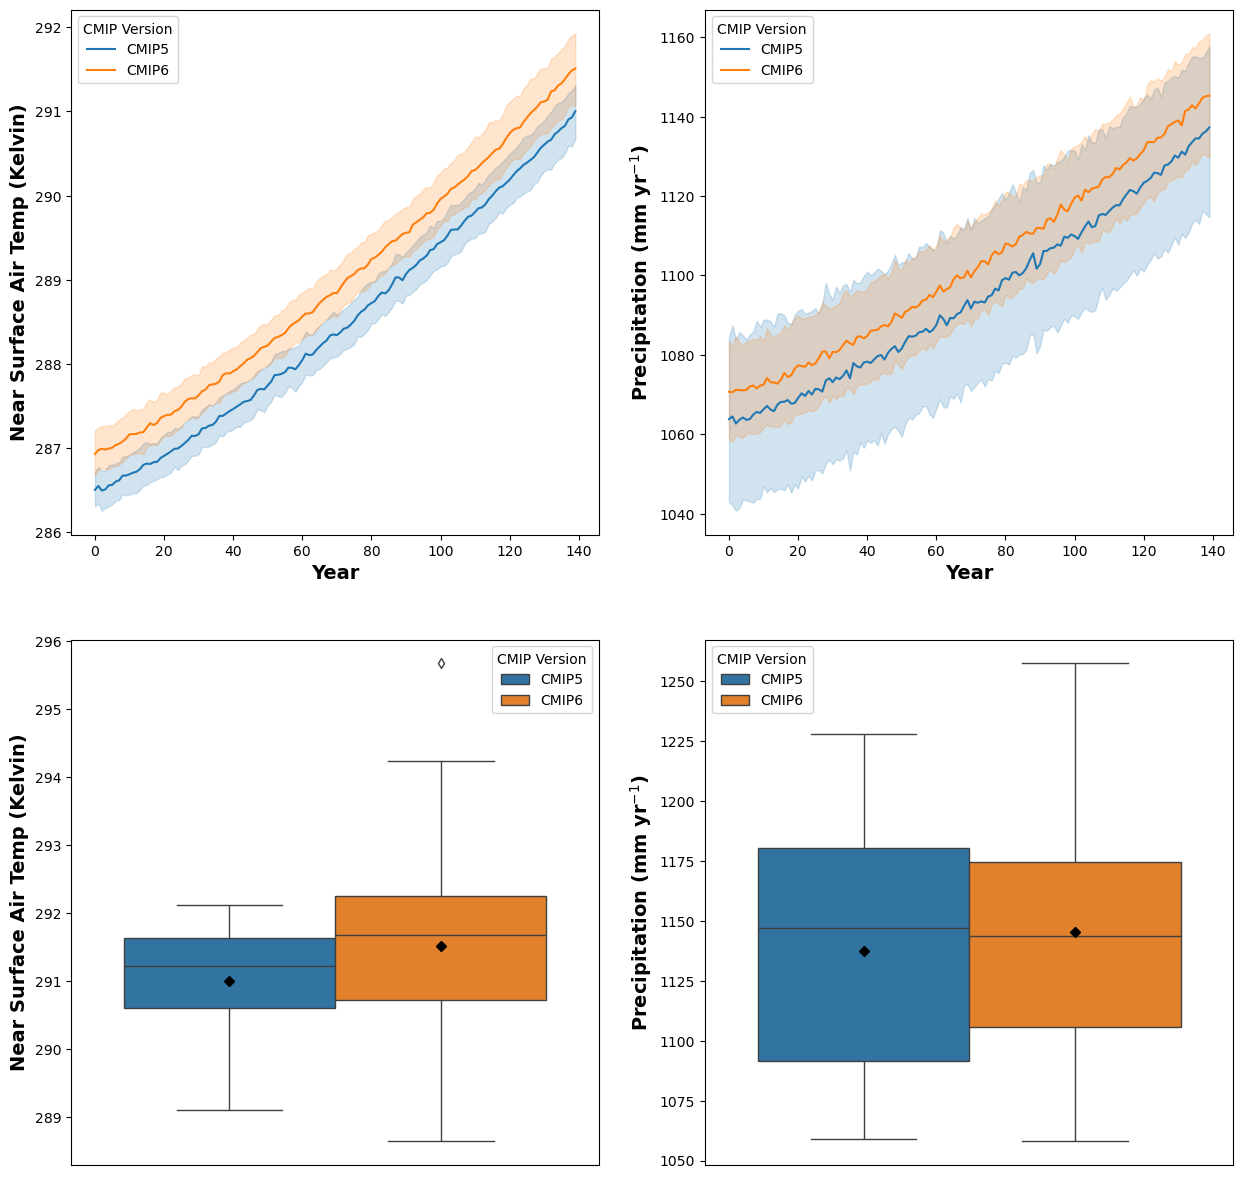

In [36]:
### Load Plotting Tools (Matplotlib and Seaborn) ###
from matplotlib import pyplot as plt
import seaborn as sns


### Convert precipitation flux to mm year-1 ###
df_all['precip mm yr-1'] = df_all['pr']*86400*365

### Grab data from Year 140 for the boxplots ###
df_boxplot = df_all[df_all['year'] == 139] #select final year of simulations. Note that Python is Zero-Indexed so it appears as year 139 here.


### Create Figures ###
fig,axs = plt.subplots(nrows=2,ncols=2,figsize=(15,15)) #initialize a 4 panel figure

mean_style={"marker":"D", "markerfacecolor":"black", "markeredgecolor":"black", "markersize":"5"} #customize the display of the ensemble mean in the boxplot
flierprops = dict(marker='d', markersize=5) #customize the display of the ensemble mean in the boxplot

## tas timeseries ##
ax1 = plt.subplot(221)
sns.lineplot(data=df_all,
            x="year", y="tas", hue='CMIP Version',
            errorbar=('ci', 95),ax=ax1)
ax1.set_ylabel('Near Surface Air Temp (Kelvin)',fontsize=14,fontweight='bold')
ax1.set_xlabel('Year',fontsize=14,fontweight='bold')

## pr timeseries ##
ax2 = plt.subplot(222)
sns.lineplot(data=df_all,
            x="year", y="precip mm yr-1", hue='CMIP Version',
            errorbar=('ci', 95),ax=ax2)
ax2.set_ylabel('Precipitation (mm yr$^{-1}$)',fontsize=14,fontweight='bold')
ax2.set_xlabel('Year',fontsize=14,fontweight='bold')

### tas boxplot ###
### Look at 5-10 year mean ###

ax3 = plt.subplot(223)
sns.boxplot(data=df_boxplot,x="year", y="tas", hue='CMIP Version',showmeans=True,meanprops=mean_style,flierprops=flierprops,ax=ax3)
ax3.set_ylabel('Near Surface Air Temp (Kelvin)',fontsize=14,fontweight='bold')
ax3.set_xlabel('') #no x-label needed for boxplots
ax3.set_xticks([]) #remove x-ticks

### pr boxplot ###
ax4 = plt.subplot(224)
sns.boxplot(df_boxplot,x="year", y="precip mm yr-1", hue='CMIP Version',showmeans=True,meanprops=mean_style,flierprops=flierprops,ax=ax4)
ax4.set_ylabel('Precipitation (mm yr$^{-1}$)',fontsize=14,fontweight='bold')
ax4.set_xlabel('') #no x-label needed for boxplots
ax4.set_xticks([]) #remove x-ticks

plt.show()

### Reflection Questions

In Module 4, you analyzed the global mean near surface air temperature (tas) and total precipitation (pr) data from the 1$\%$ yr$^{-1}$ idealized emission scenarios in the CMIP5 and CMIP6 archives. We leave you with a couple of reflection questions:

1) How do the ensemble mean temperature and precipitation differ between CMIP5 and CMIP6? What could account for their differences? (hint: look back at Module 3)
2) Comment on the differences in ensemble spread between CMIP5 and CMIP5 temperature and precipitation in Year 140. How does this relate to what you found in Module 3? 